In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Задача 1.

Исследовать на аппроксимацию и устойчивость разностную схему

$$\frac{y_k^{n+1} - y_k^n}{\tau} + \frac{a}{2} \left[ \frac{y_{k+1}^{n+1} - y_{k-1}^{n+1}}{2h} + \frac{y_{k+1}^n - y_{k-1}^n}{2h} \right] = \frac{1}{2} (f_k^{n+1} + f_k^n),$$
$$y_k^0 = \varphi (x_k) \quad k = 0, \pm 1, \dots, n = 0, 1, 2, \dots$$

для задачи

$$u_t + a u_x = f(t, x) \quad u(0, x) = \varphi(x) \quad t \ge 0 \quad -\infty < x < \infty$$

Решите численно задачу.

Исследование на аппроксимацию

Разложим сеточную функцию в ряд Тейлора в точке $(x_k, t_{n+1/2})$:
\begin{align*}
\frac{y_k^{n+1} - y_k^n}{\tau} &= u_t + \mathcal{O}(\tau^2), \\
\frac{y_{k+1}^{m} - y_{k-1}^{m}}{2h} &= u_x(t_m) + \mathcal{O}(h^2), \quad m \in \{n, n+1\}, \\
\frac{1}{2}\left[ u_x(t_{n+1}) + u_x(t_n) \right] &= u_x(t_{n+1/2}) + \mathcal{O}(\tau^2), \\
\frac{1}{2}(f_k^{n+1} + f_k^n) &= f + \mathcal{O}(\tau^2).
\end{align*}

Подставляя разложения в исходную схему, получаем уравнение с невязкой:
$$ u_t + a u_x - f = \mathcal{O}(\tau^2 + h^2). $$
Порядок аппроксимации схемы равен $\mathcal{O}(\tau^2 + h^2)$.


Исследование на устойчивость (признак фон Неймана)

Подставим гармонику $y_k^n = \lambda^n e^{i \alpha k}$ в однородную схему ($f=0$):
$$ \frac{\lambda - 1}{\tau} + \frac{a}{2} \left[ \lambda \frac{e^{i\alpha} - e^{-i\alpha}}{2h} + \frac{e^{i\alpha} - e^{-i\alpha}}{2h} \right] = 0. $$

Используя формулу Эйлера $e^{i\alpha} - e^{-i\alpha} = 2i \sin \alpha$ и вводя число Куранта $r = \frac{a\tau}{h}$, умножим на $\tau$:
$$ \lambda - 1 + i \frac{r}{2} \sin \alpha (\lambda + 1) = 0. $$

Выразим множитель перехода $\lambda$:
$$ \lambda = \frac{1 - i \frac{r}{2} \sin \alpha}{1 + i \frac{r}{2} \sin \alpha}. $$

Найдем квадрат модуля:
$$ |\lambda|^2 = \frac{1 + \frac{r^2}{4} \sin^2 \alpha}{1 + \frac{r^2}{4} \sin^2 \alpha} = 1. $$

Так как $|\lambda| = 1 \le 1$ при любых $\tau$ и $h$, схема абсолютно устойчива.

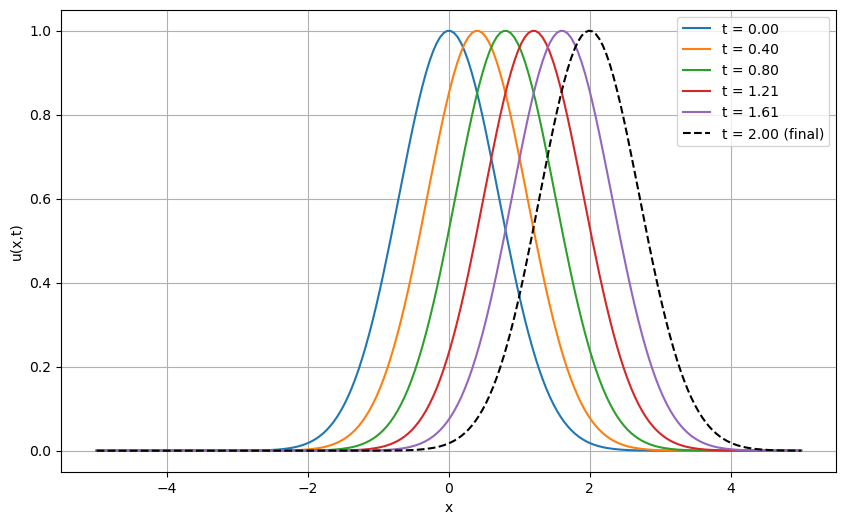

In [2]:
a = 1.0
x_min, x_max = -5.0, 5.0
T_max = 2.0
Nx = 200
Nt = 200

x = np.linspace(x_min, x_max, Nx)
t = np.linspace(0, T_max, Nt)
h = x[1] - x[0]
tau = t[1] - t[0]
C = a * tau / (4 * h)

def phi(x):
    return np.exp(-x**2)

def exact_sol(x, t, a):
    return phi(x - a*t)

u = np.zeros((Nt, Nx))
u[0, :] = phi(x)

A = np.zeros((Nx-2, Nx-2))
np.fill_diagonal(A, 1.0)
np.fill_diagonal(A[1:], -C)
np.fill_diagonal(A[:, 1:], C)

for n in range(Nt - 1):
    u[n+1, 0] = exact_sol(x[0], t[n+1], a)
    u[n+1, Nx-1] = exact_sol(x[Nx-1], t[n+1], a)
    
    RHS = np.zeros(Nx-2)
    for k in range(1, Nx-1):
        RHS[k-1] = u[n, k] + C * u[n, k-1] - C * u[n, k+1]
        
    RHS[0] += C * u[n+1, 0]
    RHS[-1] -= C * u[n+1, Nx-1]
    
    u[n+1, 1:Nx-1] = np.linalg.solve(A, RHS)

plt.figure(figsize=(10, 6))
for n in range(0, Nt, Nt//5):
    plt.plot(x, u[n, :], label=f't = {t[n]:.2f}')
plt.plot(x, u[-1, :], 'k--', label=f't = {t[-1]:.2f} (final)')
plt.xlabel('x')
plt.ylabel('u(x,t)')
plt.legend()
plt.grid(True)
plt.show()

# Задача 2.

Построить две разностные схемы для задачи с разными шаблонами
$$\frac{\partial u}{\partial t} - a^2(x, t) \frac{\partial^2 u}{\partial x^2} = 0, \quad u(x, 0) = \psi(x)$$
Спектральным признаком исследовать полученные схемы на устойчивость, используя принцип замороженных коэффициентов.

Явная разностная схема (4-точечный шаблон "крест")

Шаблон: $(t_n, x_{k-1}), (t_n, x_k), (t_n, x_{k+1}), (t_{n+1}, x_k)$.
Разностное уравнение:
$$ \frac{y_k^{n+1} - y_k^n}{\tau} = a^2(x_k, t_n) \frac{y_{k+1}^n - 2y_k^n + y_{k-1}^n}{h^2} $$

Принцип замороженных коэффициентов: локально считаем $a^2(x, t) \approx a^2 = \text{const}$. 
Подставим гармонику $y_k^n = \lambda^n e^{i \alpha k}$:
$$ \frac{\lambda - 1}{\tau} = a^2 \frac{e^{i\alpha} - 2 + e^{-i\alpha}}{h^2} = -a^2 \frac{4 \sin^2(\alpha/2)}{h^2} $$
$$ \lambda = 1 - 4 r \sin^2 \frac{\alpha}{2}, \quad \text{где } r = \frac{a^2 \tau}{h^2} $$
Для устойчивости требуется $|\lambda| \le 1$, что дает $-1 \le 1 - 4 r \sin^2(\alpha/2) \le 1$.
Схема условно устойчива при $r \le 1/2$, то есть $\tau \le \frac{h^2}{2 \max_{x,t} a^2(x,t)}$.

Неявная разностная схема (чисто неявный шаблон)

Шаблон: $(t_n, x_k), (t_{n+1}, x_{k-1}), (t_{n+1}, x_k), (t_{n+1}, x_{k+1})$.
Разностное уравнение:
$$ \frac{y_k^{n+1} - y_k^n}{\tau} = a^2(x_k, t_{n+1}) \frac{y_{k+1}^{n+1} - 2y_k^{n+1} + y_{k-1}^{n+1}}{h^2} $$

Снова считаем $a^2 = \text{const}$ и подставляем $y_k^n = \lambda^n e^{i \alpha k}$:
$$ \frac{\lambda - 1}{\tau} = \lambda a^2 \frac{-4 \sin^2(\alpha/2)}{h^2} $$
$$ \lambda - 1 = -4 r \lambda \sin^2\frac{\alpha}{2} \implies \lambda \left( 1 + 4 r \sin^2\frac{\alpha}{2} \right) = 1 $$
$$ \lambda = \frac{1}{1 + 4 r \sin^2(\alpha/2)} $$
Так как $r > 0$, знаменатель всегда $\ge 1$, следовательно, $0 < \lambda \le 1$.
Схема безусловно устойчива при любых шагах $\tau$ и $h$.

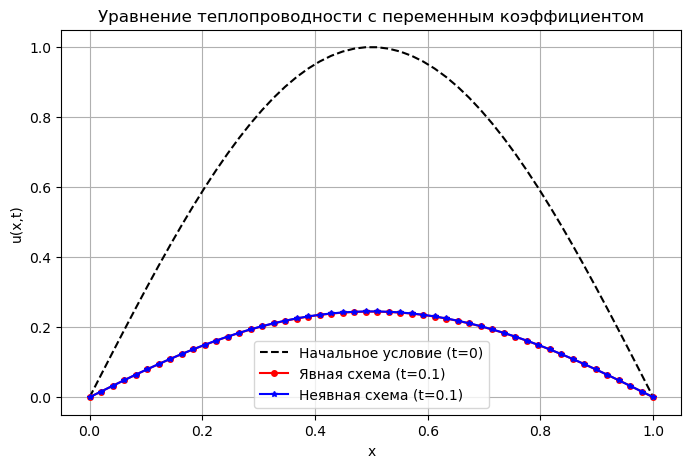

In [3]:
# 1. Параметры 
L = 1.0
T = 0.1
Nx = 50
h = L / (Nx - 1)
x = np.linspace(0, L, Nx)

# 2. Функции 
def a2(x, t):
    return 1.0 + 0.5 * np.sin(np.pi * x)  

def psi(x):
    return np.sin(np.pi * x)

# 3. Настройка времени 
max_a2 = 1.5 
tau_exp = 0.4 * h**2 / max_a2 
Nt = int(T / tau_exp) + 1
tau = T / (Nt - 1)

u_exp = np.zeros(Nx)
u_imp = np.zeros(Nx)
u_exp[:] = psi(x)
u_imp[:] = psi(x)

# 4. Вспомогательные массивы
u_new_exp = np.zeros(Nx)
A_imp = np.zeros((Nx-2, Nx-2))

# 5. Главный цикл 
for n in range(Nt - 1):
    t_n = n * tau
    t_next = (n + 1) * tau
    
    # Явная схема
    for k in range(1, Nx - 1):
        r_k = a2(x[k], t_n) * tau / h**2
        u_new_exp[k] = u_exp[k] + r_k * (u_exp[k-1] - 2*u_exp[k] + u_exp[k+1])
    u_exp[:] = u_new_exp[:]
    
    # Неявная схема 
    RHS = u_imp[1:Nx-1].copy()
    
    for i in range(Nx - 2):
        k = i + 1
        r_k = a2(x[k], t_next) * tau / h**2
        A_imp[i, i] = 1.0 + 2.0 * r_k
        if i > 0:
            A_imp[i, i-1] = -r_k
        if i < Nx - 3:
            A_imp[i, i+1] = -r_k
            
    # Неявная: Граничные условия
    RHS[0] += a2(x[1], t_next) * tau / h**2 * 0.0
    RHS[-1] += a2(x[-2], t_next) * tau / h**2 * 0.0
    
    u_imp[1:Nx-1] = np.linalg.solve(A_imp, RHS)

# 6. Отрисовка
plt.figure(figsize=(8, 5))
plt.plot(x, psi(x), 'k--', label='Начальное условие (t=0)')
plt.plot(x, u_exp, 'r-o', markersize=4, label=f'Явная схема (t={T})')
plt.plot(x, u_imp, 'b-*', markersize=4, label=f'Неявная схема (t={T})')
plt.title("Уравнение теплопроводности с переменным коэффициентом")
plt.xlabel("x")
plt.ylabel("u(x,t)")
plt.legend()
plt.grid()
plt.show()

# Задача 3.

Получите с помощью схемы переменных направлений решение двумерной задачи нестационарной теплопроводности в квадрате при следующих начальных и краевых условиях:

$$u_t = u_{xx} + u_{yy} + f(x, y, t), \quad 0 \le x \le 1, \quad 0 \le y \le 1, \quad 0 < t,$$

$$f(x, y, t) = 2\pi^2 \sin(\pi x) \sin(\pi y),$$
$$u(0, y, t) = 0, \quad u(1, y, t) = 0, \quad u(x, 0, t) = 0, \quad u(x, 1, t) = 0, \quad 0 < t,$$
$$u(x, y, 0) = 0, \quad 0 \le x \le 1, \quad 0 \le y \le 1.$$

Проверьте, что точным решением дифференциальной задачи является
$$u(x, y, t) = (1 - \exp (-\pi^2 t)) \sin(\pi x) \sin(\pi y)$$
Сгущением сеток и сравнением с сеточной проекцией точного решения покажите, что схема имеет второй порядок сходимости по всем переменным (т.е. проверить порядок аппроксимации экспериментально).

Уравнение: $u_t = u_{xx} + u_{yy} + f(x, y, t)$, где $f(x, y, t) = 2\pi^2 \sin(\pi x) \sin(\pi y)$.

Убедимся, что заданная функция $u(x, y, t) = (1 - e^{-2\pi^2 t}) \sin(\pi x) \sin(\pi y)$ является точным решением. Для этого найдем производные:
\begin{align*}
u_t &= 2\pi^2 e^{-2\pi^2 t} \sin(\pi x) \sin(\pi y) \\
u_{xx} &= -\pi^2 (1 - e^{-2\pi^2 t}) \sin(\pi x) \sin(\pi y) \\
u_{yy} &= -\pi^2 (1 - e^{-2\pi^2 t}) \sin(\pi x) \sin(\pi y)
\end{align*}

Соберем правую часть дифференциального уравнения ($u_{xx} + u_{yy} + f$):
$$ -2\pi^2(1 - e^{-2\pi^2 t})\sin(\pi x)\sin(\pi y) + 2\pi^2\sin(\pi x)\sin(\pi y) = 2\pi^2 e^{-2\pi^2 t} \sin(\pi x)\sin(\pi y) $$

Сравнивая левую часть ($u_t$) и вычисленную правую часть, видим их полное совпадение:
$$ 2\pi^2 e^{-2\pi^2 t} \sin(\pi x) \sin(\pi y) = 2\pi^2 e^{-2\pi^2 t} \sin(\pi x) \sin(\pi y) $$

Уравнение сходится тождественно, значит, предложенная функция действительно является точным решением задачи.

Сгущение сеток и проверка порядка сходимости (T = 0.1):
N     | Nt    | Max Error    | Порядок (log2)
---------------------------------------------
11    | 10    | 5.055111e-03 | -
21    | 20    | 1.262738e-03 | 2.00
41    | 40    | 3.156188e-04 | 2.00
81    | 80    | 7.890059e-05 | 2.00


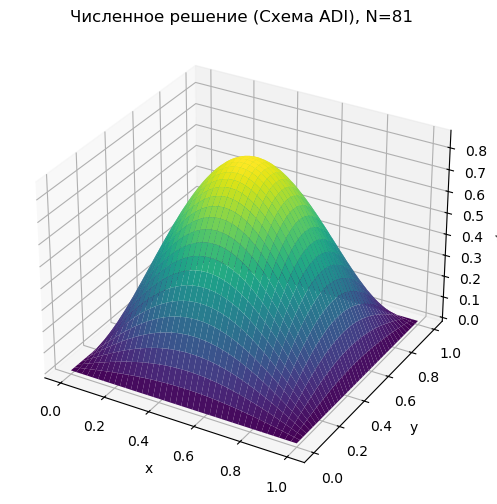

In [4]:
def exact_u(x, y, t):
    return (1.0 - np.exp(-2.0 * np.pi**2 * t)) * np.sin(np.pi * x) * np.sin(np.pi * y)

def f_source(x, y):
    return 2.0 * np.pi**2 * np.sin(np.pi * x) * np.sin(np.pi * y)

def solve_adi(N, Nt, T_end):
    h = 1.0 / (N - 1)
    tau = T_end / Nt
    r = tau / (2.0 * h**2)
    
    x = np.linspace(0, 1, N)
    y = np.linspace(0, 1, N)
    X, Y = np.meshgrid(x, y, indexing='ij')
    F = f_source(X, Y)
    
    m = N - 2
    A = np.zeros((m, m))
    np.fill_diagonal(A, 1 + 2*r)
    np.fill_diagonal(A[1:], -r)
    np.fill_diagonal(A[:, 1:], -r)
    
    u = np.zeros((N, N))
    u_half = np.zeros((N, N))
    
    for n in range(Nt):
        # Шаг 1: неявно по X, явно по Y
        for j in range(1, N - 1):
            RHS = np.zeros(m)
            for i in range(1, N - 1):
                RHS[i-1] = u[i, j] + r * (u[i, j-1] - 2*u[i, j] + u[i, j+1]) + (tau / 2) * F[i, j]
            u_half[1:N-1, j] = np.linalg.solve(A, RHS)
            
        # Шаг 2: явно по X, неявно по Y
        for i in range(1, N - 1):
            RHS = np.zeros(m)
            for j in range(1, N - 1):
                RHS[j-1] = u_half[i, j] + r * (u_half[i-1, j] - 2*u_half[i, j] + u_half[i+1, j]) + (tau / 2) * F[i, j]
            u[i, 1:N-1] = np.linalg.solve(A, RHS)
            
    u_ex = exact_u(X, Y, T_end)
    error = np.max(np.abs(u - u_ex))
    return error, u, X, Y

T_end = 0.1
grid_sizes =[11, 21, 41, 81] 
errors =[]

print("Сгущение сеток и проверка порядка сходимости (T = 0.1):")
print(f"{'N':<5} | {'Nt':<5} | {'Max Error':<12} | {'Порядок (log2)'}")
print("-" * 45)

for i, N in enumerate(grid_sizes):
    Nt = N - 1  # Уменьшаем h и tau пропорционально, чтобы видеть общий порядок O(tau^2 + h^2)
    err, u_num, X, Y = solve_adi(N, Nt, T_end)
    errors.append(err)
    
    if i == 0:
        print(f"{N:<5} | {Nt:<5} | {err:.6e} | -")
    else:
        # Экспериментальный порядок сходимости = log2(E_prev / E_curr)
        order = np.log2(errors[i-1] / errors[i])
        print(f"{N:<5} | {Nt:<5} | {err:.6e} | {order:.2f}")

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, Y, u_num, cmap='viridis')
ax.set_title(f'Численное решение (Схема ADI), N={grid_sizes[-1]}')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('u(x,y,t)')
plt.show()

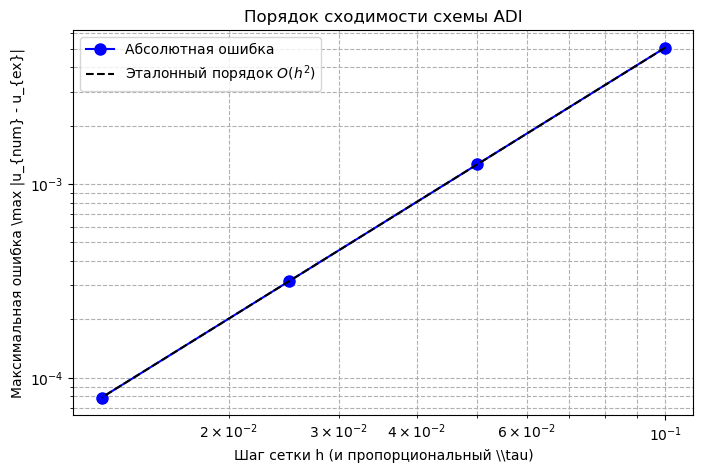

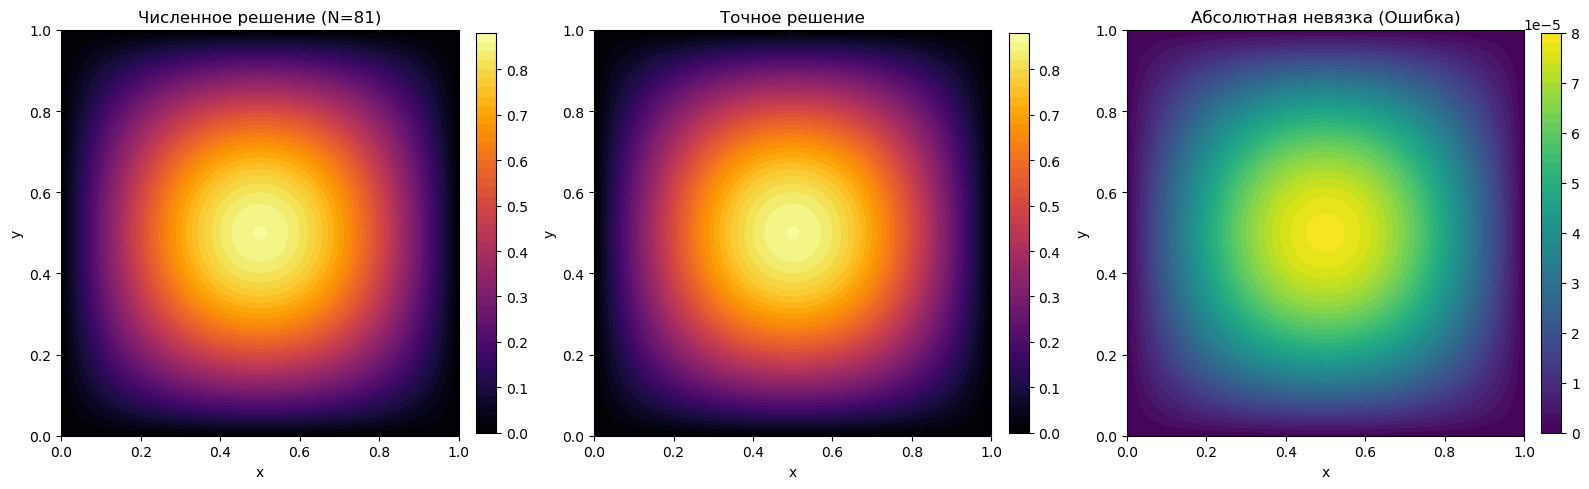

In [5]:
# --- 1. График сходимости ---
h_values = 1.0 / (np.array(grid_sizes) - 1)

plt.figure(figsize=(8, 5))
plt.loglog(h_values, errors, 'b-o', markersize=8, label='Абсолютная ошибка')

# Добавляем эталонную прямую второго порядка (y = C * x^2)
# Привяжем её к последней точке для красивого совмещения
reference_line = errors[-1] * (h_values / h_values[-1])**2 
plt.loglog(h_values, reference_line, 'k--', label='Эталонный порядок $O(h^2)$')

plt.title(r'Порядок сходимости схемы ADI')
plt.xlabel(r'Шаг сетки h (и пропорциональный \\tau)')
plt.ylabel(r'Максимальная ошибка \max |u_{num} - u_{ex}|')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

# --- 2 и 3. Тепловые карты ---
u_exact = exact_u(X, Y, T_end)
abs_error_map = np.abs(u_num - u_exact)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Численное решение
im0 = axes[0].contourf(X, Y, u_num, levels=50, cmap='inferno')
axes[0].set_title(f'Численное решение (N={grid_sizes[-1]})')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# Точное решение
im1 = axes[1].contourf(X, Y, u_exact, levels=50, cmap='inferno')
axes[1].set_title('Точное решение')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# Карта ошибки
im2 = axes[2].contourf(X, Y, abs_error_map, levels=50, cmap='viridis')
axes[2].set_title('Абсолютная невязка (Ошибка)')
axes[2].set_xlabel('x')
axes[2].set_ylabel('y')
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# Задача 4.

Построить разностную схему для решения задачи

$$\frac{\partial}{\partial x} \left( u \frac{\partial u}{\partial x} \right) + \frac{\partial}{\partial y} \left( u \frac{\partial u}{\partial y} \right) = 0$$

в прямоугольной области $0 \le x \le X, 0 \le y \le Y$ с граничными условиями

$$u(0, y) = 1, \quad u(x, Y) = 1 + x^2, \quad u(X, y) = 1 + X^2 y/Y, \quad u(x, 0) = 1$$

Какой порядок аппроксимации у данной численной схемы? Является ли это уравнение линейным? Решите задачу.

Является ли уравнение линейным?
данное уравнение является квазилинейным, так как коэффициенты при производных зависят от самой искомой функции $u$.

Построение консервативной разностной схемы

Для квазилинейных уравнений дивергентного вида схему строим с использованием промежуточных узлов, чтобы соблюдался закон сохранения.
Введем сетку $(x_i, y_j) = (i h_x, j h_y)$. Аппроксимируем производные:
$$ \frac{1}{h_x} \left( a_{i+1/2, j} \frac{u_{i+1,j} - u_{i,j}}{h_x} - a_{i-1/2, j} \frac{u_{i,j} - u_{i-1,j}}{h_x} \right) + \frac{1}{h_y} \left( b_{i, j+1/2} \frac{u_{i,j+1} - u_{i,j}}{h_y} - b_{i, j-1/2} \frac{u_{i,j} - u_{i,j-1}}{h_y} \right) = 0 $$

В нашем случае коэффициенты диффузии $a(u) = b(u) = u$. В качестве значения в полуцелых узлах возьмем среднее арифметическое:
$$ a_{i+1/2, j} \approx \frac{u_{i+1,j} + u_{i,j}}{2} $$

Заметим красивый математический факт. При такой аппроксимации поток равен:
$$ a_{i+1/2, j} \frac{u_{i+1,j} - u_{i,j}}{h_x} = \frac{u_{i+1,j} + u_{i,j}}{2} \frac{u_{i+1,j} - u_{i,j}}{h_x} = \frac{u_{i+1,j}^2 - u_{i,j}^2}{2h_x} $$

Тогда вся пространственная часть (оператор $\Lambda$) сводится к:
$$ \Lambda[u] = \frac{u_{i+1,j}^2 - 2u_{i,j}^2 + u_{i-1,j}^2}{2 h_x^2} + \frac{u_{i,j+1}^2 - 2u_{i,j}^2 + u_{i,j-1}^2}{2 h_y^2} = 0 $$

Использование центральных разностей и средних значений в полуцелых узлах дает схеме порядок аппроксимации $\mathcal{O}(h_x^2 + h_y^2)$.

Установление достигнуто на итерации 8830. Ошибка: 1.00e-06


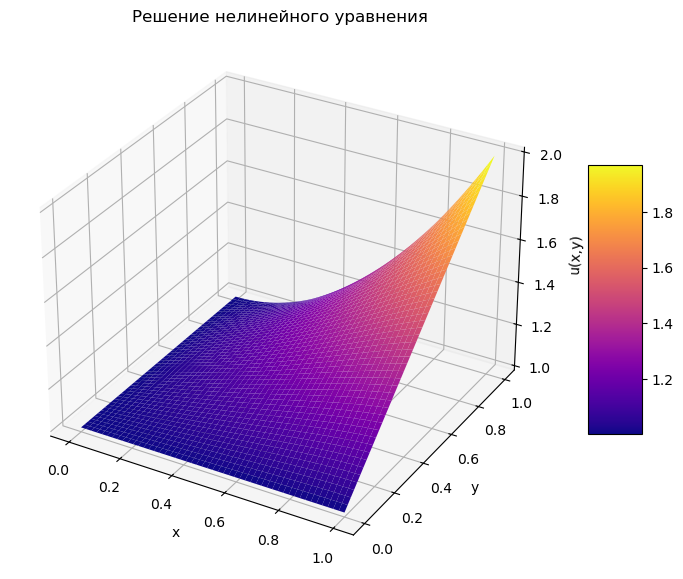

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Параметры области и сетки
X_len = 1.0
Y_len = 1.0
Nx = 50
Ny = 50
hx = X_len / (Nx - 1)
hy = Y_len / (Ny - 1)

x = np.linspace(0, X_len, Nx)
y = np.linspace(0, Y_len, Ny)
X, Y = np.meshgrid(x, y, indexing='ij')

# 2. Инициализация функции u и краевых условий
u = np.ones((Nx, Ny))

u[0, :] = 1.0                           # u(0, y) = 1
u[-1, :] = 1.0 + X_len**2 * y / Y_len   # u(X, y) = 1 + X^2 y/Y
u[:, 0] = 1.0                           # u(x, 0) = 1
u[:, -1] = 1.0 + x**2                   # u(x, Y) = 1 + x^2

# 3. Настройка итерационного процесса (метод установления)
max_iter = 50000
tolerance = 1e-6
max_u = np.max(u)
# Шаг по искусственному времени с условием Куранта (с учетом нелинейности ~ u)
tau = 0.25 / (max_u * (1/hx**2 + 1/hy**2))  

# 4. Основной цикл установления 
for it in range(max_iter):
    u_old = u.copy()
    
    # Квадрат функции
    u2 = u**2 
    
    # Оператор Лапласа от u^2
    laplace_u2 = (u2[2:, 1:-1] - 2*u2[1:-1, 1:-1] + u2[:-2, 1:-1]) / hx**2 + \
                 (u2[1:-1, 2:] - 2*u2[1:-1, 1:-1] + u2[1:-1, :-2]) / hy**2
    
    u[1:-1, 1:-1] = u[1:-1, 1:-1] + tau * 0.5 * laplace_u2
    
    diff = np.max(np.abs(u - u_old))
    if diff < tolerance:
        print(f"Установление достигнуто на итерации {it}. Ошибка: {diff:.2e}")
        break

# 5. Визуализация результата
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, Y, u, cmap='plasma', edgecolor='none')
ax.set_title('Решение нелинейного уравнения')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('u(x,y)')
fig.colorbar(surf, shrink=0.5, aspect=5)
plt.show()

# Задача 5.**

Требуется решить двумерное уравнение Пуассона: $u_{xx} + u_{yy} = f(x, y)$, на многосвязной области интегрирования с нулевым начальным приближением и различными граничными условиями первого или второго типа. Граница может быть произвольно заданной замкнутой кривой без самопересечений.

Эта задача с двумя звёздочками - вполне можно за неё одну дать БРСов как за всё задание.


Решается уравнение Пуассона:
$$ \Delta u = f(x, y) \implies \frac{u_{i+1,j} - 2u_{i,j} + u_{i-1,j}}{h^2} + \frac{u_{i,j+1} - 2u_{i,j} + u_{i,j-1}}{h^2} = f_{i,j} $$

**Многосвязная область:**
Пусть $\Omega$ — наша область интегрирования. Зададим её программно как пересечение геометрических условий (например, внутри большого круга, но вне малого).

**Граничные условия (ГУ):**

1. **Первого рода (Дирихле) $u = \varphi(x,y)$**: На узлах сетки, оказавшихся снаружи, но вплотную к внешней границе $\Gamma_1$, просто фиксируем заданное значение $u_{i,j} = 0$.

2. **Второго рода (Неймана) $\frac{\partial u}{\partial \vec{n}} = 0$**: На внутренней границе $\Gamma_2$ (вырезе). Как указано в учебных материалах, производную по нормали $\vec{n} = (n_x, n_y)$ можно аппроксимировать, опираясь на внутренние узлы. 
Если кривая задана уравнением $F(x,y) = 0$, то нормаль вычисляется как $\vec{n} = \frac{\nabla F}{|\nabla F|}$. 
Для дискретизации условия $\nabla u \cdot \vec{n} = 0$ мы будем проецировать граничный узел $(i, j)$ вдоль нормали на ближайший внутренний узел сетки и приравнивать их значения: 
$$ u_{i,j} \approx u(x_i + h \cdot n_x, y_j + h \cdot n_y) $$

Итерационный процесс (метод Якоби) начинается с нулевого начального приближения $u^0 \equiv 0$ и продолжается до сходимости.

Решение сошлось на итерации 9839 (Невязка: 1.00e-06)


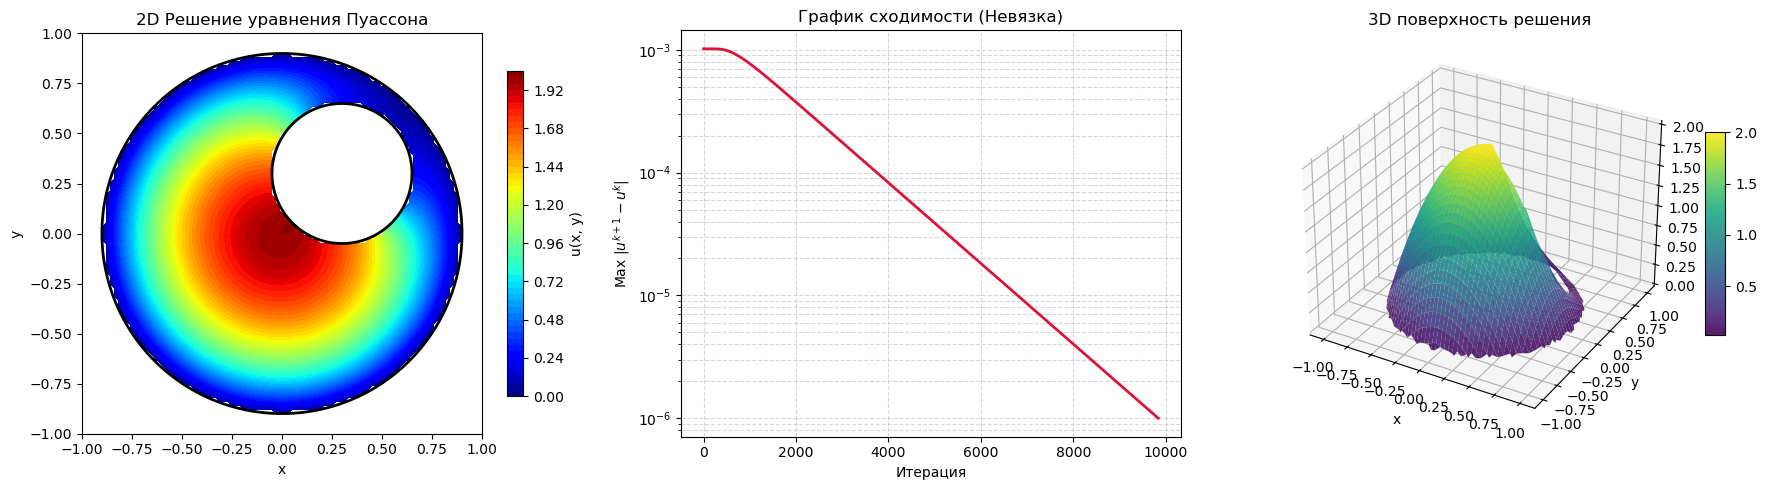

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation

# 1. Параметры сетки и области
N = 100
L = 1.0
h = 2 * L / (N - 1)
x = np.linspace(-L, L, N)
y = np.linspace(-L, L, N)
X, Y = np.meshgrid(x, y, indexing='ij')

# 2. Создание многосвязной геометрии
R_outer = 0.9
dist_outer = np.sqrt(X**2 + Y**2)

cx, cy = 0.3, 0.3
R_inner = 0.35
dist_inner = np.sqrt((X - cx)**2 + (Y - cy)**2)

domain = (dist_outer <= R_outer) & (dist_inner >= R_inner)

# 3. Выделение масок границ
domain_dilated = binary_dilation(domain)
boundary = domain_dilated ^ domain

mask_dirichlet = boundary & (dist_outer > R_outer)
mask_neumann = boundary & (dist_inner < R_inner)

# 4. Нормали для условия Неймана (внутренняя граница)
nx = (X[mask_neumann] - cx) / R_inner
ny = (Y[mask_neumann] - cy) / R_inner

shift_x = np.round(nx).astype(int)
shift_y = np.round(ny).astype(int)

idx_x, idx_y = np.where(mask_neumann)
target_x = np.clip(idx_x + shift_x, 0, N - 1)
target_y = np.clip(idx_y + shift_y, 0, N - 1)

# 5. Инициализация массивов
u = np.zeros((N, N))
u_new = np.zeros((N, N))
f = -10.0 * np.ones((N, N))  

# 6. УЛУЧШЕННЫЙ ОСНОВНОЙ ЦИКЛ
max_iter = 10000
tol = 1e-6               # Порог сходимости
res_history =[]

# Предрасчет неизменяемой части уравнения для ускорения
rhs_term = - (h**2) * f[1:-1, 1:-1] 

for it in range(max_iter):
    # 6.1. Решение Пуассона (Якоби)
    u_new[1:-1, 1:-1] = 0.25 * (u[2:, 1:-1] + u[:-2, 1:-1] + 
                                u[1:-1, 2:] + u[1:-1, :-2] + rhs_term)
    
    # 6.2. Применение масок и ГУ
    u_new[~domain] = 0.0
    u_new[mask_dirichlet] = 0.0                        # ГУ 1-го рода (внешняя)
    u_new[idx_x, idx_y] = u_new[target_x, target_y]    # ГУ 2-го рода (внутренняя)
    
    # 6.3. Расчет невязки и проверка сходимости
    diff = np.max(np.abs(u_new - u))
    res_history.append(diff)
    
    # Обновление массива без копирования объектов в памяти
    u[:] = u_new
    
    if diff < tol:
        print(f"Решение сошлось на итерации {it} (Невязка: {diff:.2e})")
        break

# 7. ВИЗУАЛИЗАЦИЯ (Объединенная)
u_plot = u.copy()
u_plot[~domain] = np.nan # Маскируем неиспользуемую область

fig = plt.figure(figsize=(18, 5))

# --- График 1: 2D Контур ---
ax1 = fig.add_subplot(1, 3, 1)
cf = ax1.contourf(X, Y, u_plot, levels=50, cmap='jet')
fig.colorbar(cf, ax=ax1, label='u(x, y)', shrink=0.8)
ax1.contour(X, Y, dist_outer, levels=[R_outer], colors='black', linewidths=2)
ax1.contour(X, Y, dist_inner, levels=[R_inner], colors='black', linewidths=2)
ax1.set_title('2D Решение уравнения Пуассона')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_aspect('equal')

# --- График 2: Сходимость ---
ax2 = fig.add_subplot(1, 3, 2)
ax2.semilogy(res_history, color='crimson', lw=2)
ax2.set_title('График сходимости (Невязка)')
ax2.set_xlabel('Итерация')
ax2.set_ylabel('Max $|u^{k+1} - u^k|$')
ax2.grid(True, which="both", ls="--", alpha=0.5)

# --- График 3: 3D Поверхность ---
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
surf = ax3.plot_surface(X, Y, u_plot, cmap='viridis', edgecolor='none', alpha=0.9)
ax3.set_title('3D поверхность решения')
ax3.set_xlabel('x')
ax3.set_ylabel('y')
ax3.set_zlabel('u')
fig.colorbar(surf, ax=ax3, shrink=0.5, aspect=10)

plt.tight_layout()
plt.show()